# 10.16 test — RBF GP Baseline Results

This is Johnson Ji 10.16 test report, includes 2 tests:

1. Use the current 3D GP implementation with an RBF kernel to reconstruct a synthetic temperature field and test spatial extrapolation and future-time prediction. The field is predefined, but the GP receives only randomly sampled sparse noisy measurements. This represents limited measurement availability, not GP-selected sampling points or a robot trajectory.

2. Use the Dashboard temperature series from Oct 14, 2026 at 00:00 to Oct 16, 2026 at 10:30 for missing-interval reconstruction and future-time prediction. This is a temporal-only test; no spatial coordinates are inferred. Exported timestamps have no specified timezone.

I use the RMSE & 95% coverage (mainly) to evaluate the performance. Note: this is the baseline test, I will potentially compare different kernel after.

The Implementation references section links to the shared model, data generation, training, evaluation and plotting source files. Folder locations and rerun commands are in [README.md](README.md).


### The explianation for how the kernel be training and how to predict the temperature

### 1. GP Model

We model the spatiotemporal temperature field using a Gaussian Process:

$$
f(z)\sim GP(m(z),k(z,z'))
$$

where:

- $z=(x,y,t)$: Spatial position and timestamp.
- $f(z)$: Unknown temperature field.
- $m(z)$: Prior mean function.
- $k(z,z')$: Kernel function describing spatiotemporal covariance.

The observed temperature is:

$$
Y_i=f(z_i)+\epsilon_i
$$

where $\epsilon_i\sim\mathcal{N}(0,\sigma_n^2)$ represents independent Gaussian measurement noise.

### 2. Kernel Training

#### 2.1 Kernel Definition

We initially use a 3D ARD RBF Kernel:

$$
k(z_i,z_j)=\sigma_f^2\exp\left[
-\frac12\left(
\frac{(x_i-x_j)^2}{\ell_x^2}
+\frac{(y_i-y_j)^2}{\ell_y^2}
+\frac{(t_i-t_j)^2}{\ell_t^2}
\right)
\right]
$$

Parameters:

- $\ell_x,\ell_y$: Spatial lengthscales.
- $\ell_t$: Temporal lengthscale.
- $\sigma_f^2$: Kernel output variance.
- $\sigma_n^2$: Measurement noise variance.
- $m$: Mean function parameters.

The kernel type is selected manually. Its hyperparameters are learned from measurements.

#### 2.2 Training Objective

Given training data:

$$
D=\{(z_i,Y_i)\}_{i=1}^{N}
$$

GP training maximizes the Log Marginal Likelihood:

$$
\theta^*=\arg\max_\theta \log p(Y\mid X,\theta)
$$

where:

- $X$: Observed positions and timestamps.
- $Y$: Observed temperatures.
- $\theta$: GP model parameters.
- $\theta^*$: Optimized parameters.

Define:

$$
K_{XX}=k(X,X)
$$

$$
C=K_{XX}+\sigma_n^2I
$$

Then:

$$
Y\mid X,\theta\sim\mathcal{N}(m_X,C)
$$

The Log Marginal Likelihood is:

$$
\log p(Y\mid X,\theta)
=
-\frac12(Y-m_X)^TC^{-1}(Y-m_X)
-\frac12\log|C|
-\frac N2\log(2\pi)
$$

The three terms represent:

1. Data fit: Consistency between observations and the GP model.
2. Covariance complexity: Penalizes excessively broad covariance distributions.
3. Normalization constant.

Training procedure:

1. Initialize GP parameters $\theta$.
2. Compute the kernel covariance matrix $K_{XX}$.
3. Calculate the Negative Log Marginal Likelihood.
4. Compute gradients using automatic differentiation.
5. Update parameters using Adam.
6. Repeat until the training procedure finishes.

Training learns the covariance structure, mean parameters, and measurement noise.

### 3. GP Posterior Prediction

After training, the optimized parameters $\theta^*$ are used to predict temperatures at unobserved locations.

#### 3.1 Posterior Mean

$$
\mu_*=
m_*+
K_{*X}(K_{XX}+\sigma_n^2I)^{-1}(Y-m_X)
$$

where:

- $m_*$: Prior mean at the query location.
- $m_X$: Prior means at observed locations.
- $Y-m_X$: Difference between measurements and prior means.
- $K_{*X}$: Covariance between query and observed locations.
- $K_{XX}$: Covariance among observed locations.

Interpretation:

$$
\text{Posterior Mean}
=
\text{Prior Mean}
+
\text{Measurement Correction}
$$

The kernel determines how strongly each measurement influences the prediction.

#### 3.2 Posterior Variance

$$
\Sigma_*=
K_{**}
-
K_{*X}(K_{XX}+\sigma_n^2I)^{-1}K_{X*}
$$

where:

- $K_{**}$: Prior covariance at query locations.
- $\Sigma_*$: Posterior covariance of the latent temperature field.

The diagonal elements of $\Sigma_*$ represent prediction uncertainty.

For noisy future measurements, observation noise must also be included:

$$
\operatorname{Var}(Y_*\mid D)=\Sigma_*+\sigma_n^2I
$$

### 4. Online GP Update

When the robot collects a new temperature measurement:

$$
D_{\text{new}}=D_{\text{old}}\cup\{(z_{\text{new}},Y_{\text{new}})\}
$$

Two updating strategies are possible:

**Method A: Fixed Hyperparameters**

- Keep the trained kernel parameters unchanged.
- Add the new measurement to the conditioning dataset.
- Recompute the GP posterior mean and covariance.
- No kernel retraining is required.

**Method B: Adaptive Hyperparameters**

- Add new measurements.
- Re-optimize GP hyperparameters using the updated dataset.
- Recompute the posterior using the updated parameters.

Our existing 2D GP/GRG notebook follows Method A during simulated online sampling.

### 5. Summary

GP Training:

$$
(X,Y)\rightarrow\theta^*
$$

Learns the kernel, mean, and noise parameters.

GP Prediction:

$$
(X,Y,\theta^*)\rightarrow(\mu_*,\Sigma_*)
$$

Uses trained parameters and observed temperatures to predict the field.

Online Update:

$$
D_{\text{new}}\rightarrow\text{Updated GP Posterior}
$$

In summary:

- Kernel parameters describe spatiotemporal correlations.
- Measurements provide actual temperature information.
- Posterior mean estimates unknown temperatures.
- Posterior covariance quantifies prediction uncertainty.
- New measurements update the posterior without necessarily retraining the kernel.


In [1]:
# Environment setup
from pathlib import Path
import csv
import html
import json
import sys
import warnings

import numpy as np
import torch
from IPython.display import Code, HTML, Image, Markdown, display

warnings.filterwarnings("ignore", message=r".*torch.jit.script.*", category=FutureWarning)
torch.set_num_threads(1)
GROUP_SYN = "3D_time&spatial temp field rebuild & prediction"
GROUP_REAL = "dashboard time temp prediction"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "10.16_testing_code" / GROUP_SYN / "gp_model.py").exists())
CODE_ROOT = ROOT / "10.16_testing_code"
SYN = ROOT / "10.16_result" / GROUP_SYN
REAL = ROOT / "10.16_result" / GROUP_REAL
sys.path.insert(0, str(CODE_ROOT / GROUP_SYN))
sys.path.insert(0, str(CODE_ROOT / GROUP_REAL))
from gp_model import load_gp
from evaluation import distribution_metrics
from dashboard_experiment import load_data, split_indices

def rows(path):
    with path.open(newline="") as f:
        return list(csv.DictReader(f))

def table(records):
    fields = list(dict.fromkeys(k for r in records for k in r))
    def cell(v):
        if isinstance(v, (float, np.floating)):
            return f"{v:.6g}"
        return html.escape(str(v))
    head = "".join(f"<th>{html.escape(k)}</th>" for k in fields)
    body = "".join("<tr>" + "".join(f"<td>{cell(r.get(k, ''))}</td>" for k in fields)
                   + "</tr>" for r in records)
    display(HTML("<table><thead><tr>" + head + "</tr></thead><tbody>" + body + "</tbody></table>"))

def figure(folder, filename):
    display(Image(filename=str(folder / "figures" / filename)))

def source(folder, files):
    for filename in files:
        display(Markdown("#### " + filename))
        display(Code(filename=str(folder / filename), language="python"))

print("Saved-checkpoint replay; temperature in °C, time in hours, space in metres.")

Saved-checkpoint replay; temperature in °C, time in hours, space in metres.


## 1. Synthetic spatiotemporal GP: reconstruction and prediction

Objective: assess whether the existing RBF GP reconstructs a known temperature field from sparse noisy measurements and predicts held-out spatial or future-time regions. Inputs are (x, y, t); output is temperature. The field is synthetic, not Dashboard-derived or a validated physical model.

### 1.1 Shared setup and checkpoint replay

Domain: 30 × 30 m over 24 h. Each main protocol uses 240 training, 80 validation and 800 independent test measurements, with Gaussian measurement-noise SD 0.2 °C. Coordinates are randomly sampled, not selected by the GP and not generated from a robot route. The ground-truth maps below define the reconstruction target.

Method: spatial ARD RBF × temporal RBF, equivalent to a 3D ARD RBF, with a Gaussian likelihood. Scaling uses training measurements only. Adam optimizes exact marginal likelihood; validation observation NLPD selects each checkpoint. Noise-free truth and test labels are excluded from fitting and checkpoint selection.


{
  "experiment": "synthetic_3d_ard_rbf_baseline",
  "scope": "Phases 0, 1, 2 only",
  "seed": 0,
  "domain": [
    [
      0.0,
      30.0
    ],
    [
      0.0,
      30.0
    ],
    [
      0.0,
      24.0
    ]
  ],
  "snapshot_hours": [
    6.0,
    12.0,
    18.0
  ],
  "grid_size": 51,
  "train_count": 240,
  "validation_count": 80,
  "test_count": 800,
  "noise_std_c": 0.2,
  "training": {
    "iterations": 400,
    "learning_rate": 0.04,
    "validation_every": 20,
    "initial_lengthscale_scaled": 0.8,
    "initial_noise_variance_scaled": 0.02,
    "dtype": "float64",
    "device": "cpu",
    "threads": 1
  },
  "spatial_split": {
    "train_x_m": [
      0.0,
      18.0
    ],
    "validation_x_m": [
      0.0,
      18.0
    ],
    "test_x_m": [
      22.0,
      30.0
    ]
  },
  "temporal_split": {
    "train_t_h": [
      0.0,
      16.0
    ],
    "validation_t_h": [
      16.0,
      18.0
    ],
    "test_t_h": [
      18.0,
      24.0
    ]
  },
  "robustness": {
    "train_counts": [
      60,
      120,
      240
    ],
    "noise_std_c": [
      0.05,
      0.2,
      0.5
    ],
    "seeds": [
      0,
      1,
      2
    ]
  }
}

protocol,train,validation,test
main,240,80,800
spatial,240,80,800
temporal,240,80,800


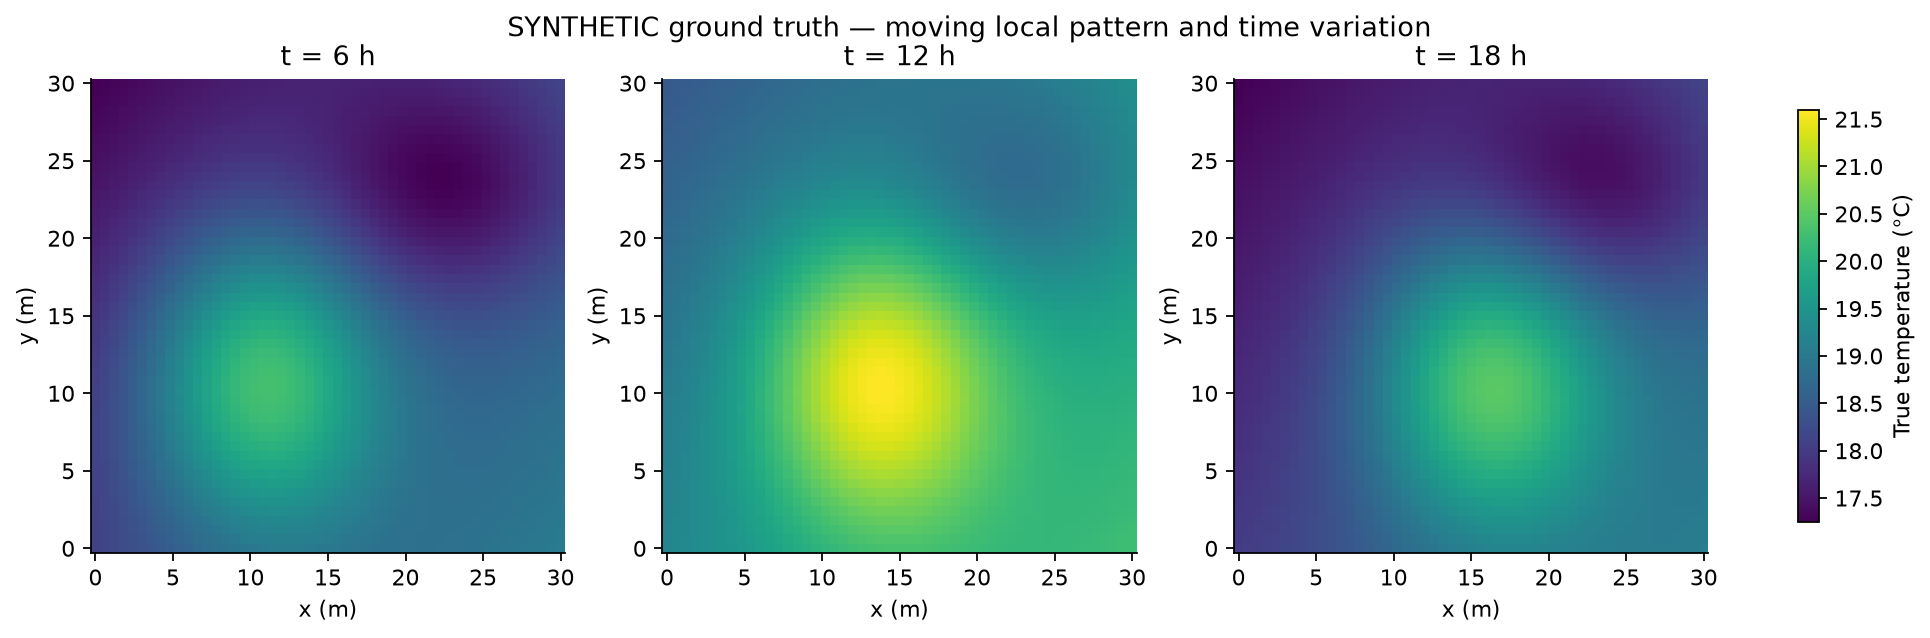

In [2]:
syn_config = json.loads((SYN / "config.json").read_text())
display(Code(json.dumps(syn_config, indent=2), language="json"))
protocols = []
for case in ["main", "spatial", "temporal"]:
    count = {split: len(rows(SYN / case / (split + ".csv")))
             for split in ["train", "validation", "test"]}
    protocols.append({"protocol": case, **count})
table(protocols)
figure(SYN, "ground_truth.png")

This notebook loads three separately trained models, recomputes their held-out posterior moments and metrics, and checks them against saved artifacts. It does not retrain them. Each result below includes its own hyperparameters, metrics and sampling figure.


In [3]:
models = {}
evaluated = []
for case in ["main", "spatial", "temporal"]:
    model = models[case] = load_gp(SYN / case / "model.pt")
    with np.load(SYN / case / "test_predictions.npz") as saved:
        pred = model.predict(saved["xyt"])
        for key in ["mean", "latent_var", "observed_var"]:
            np.testing.assert_allclose(pred[key], saved[key], rtol=1e-9, atol=1e-10)
        for target, actual, variance in [
            ("latent_truth", saved["truth"], pred["latent_var"]),
            ("noisy_observation", saved["observed"], pred["observed_var"])]:
            evaluated.append({"scenario": case, "target": target,
                              **distribution_metrics(actual, pred["mean"], variance)})

saved_metrics = rows(SYN / "metrics.csv")
assert len(saved_metrics) == len(evaluated)
for computed in evaluated:
    recorded = next(r for r in saved_metrics
                    if r["scenario"] == computed["scenario"] and r["target"] == computed["target"])
    for key in ["rmse_c", "mae_c", "coverage_95", "nlpd", "interval_width_95_c", "z_mean", "z_std"]:
        np.testing.assert_allclose(computed[key], float(recorded[key]), rtol=1e-8, atol=1e-9)


def show_test_result(case):
    model = models[case]
    hp = model.hyperparameters()
    table([{"protocol": case, "selected_iteration": model.selected_iteration,
            "lengthscales_m_m_h": hp["lengthscales_m_m_h"],
            "noise_variance_c2": hp["noise_variance_c2"]}])
    table([r for r in evaluated if r["scenario"] == case])

print("Three independent checkpoints loaded; saved predictions and metrics verified.")

Three independent checkpoints loaded; saved predictions and metrics verified.


### 1.2 Results of the three tests

| Test                                   | Purpose                                                                    | Training and validation region               | Test region                                   |
| -------------------------------------- | -------------------------------------------------------------------------- | -------------------------------------------- | --------------------------------------------- |
| 1. In-domain reconstruction (`main`)   | Recover temperatures between sparse measurements within the sampled domain | Full x/y/t domain                            | Independent points throughout the same domain |
| 2. Spatial extrapolation (`spatial`)   | Predict temperatures outside the measured x-region                         | x ∈ [0, 18] m; full y/time range             | x ∈ [22, 30] m                                |
| 3. Future-time prediction (`temporal`) | Predict temperatures beyond the training time range                        | Train t ∈ [0, 16] h; validate t ∈ [16, 18] h | t ∈ [18, 24] h                                |

RMSE and MAE measure temperature error. Central 95% coverage and interval width assess predictive uncertainty; NLPD evaluates the Gaussian predictive distribution. `latent_truth` uses noise-free temperature and latent variance; `noisy_observation` uses noisy temperature and observation variance. These are two evaluation targets for the same fitted model, not different prediction methods.

#### Test 1 — In-domain temperature-field reconstruction

Purpose: recover the field within the sampled space-time domain. This is offline reconstruction using sparse training measurements across the full 0–24 h interval, including observations later than a displayed snapshot; it is not a causal forecast. The following outputs show the main-model parameters, held-out metrics, sampling distribution and training history. Validation selects iteration 40.


protocol,selected_iteration,lengthscales_m_m_h,noise_variance_c2
main,40,"[9.251693775512932, 10.859734940230167, 7.352885768035894]",0.043504


scenario,target,rmse_c,mae_c,coverage_95,nlpd,interval_width_95_c,z_mean,z_std
main,latent_truth,0.110456,0.0870401,0.9775,-0.809678,0.507668,0.0237354,0.883243
main,noisy_observation,0.225215,0.179934,0.96875,-0.0700108,0.97813,0.0105605,0.904251


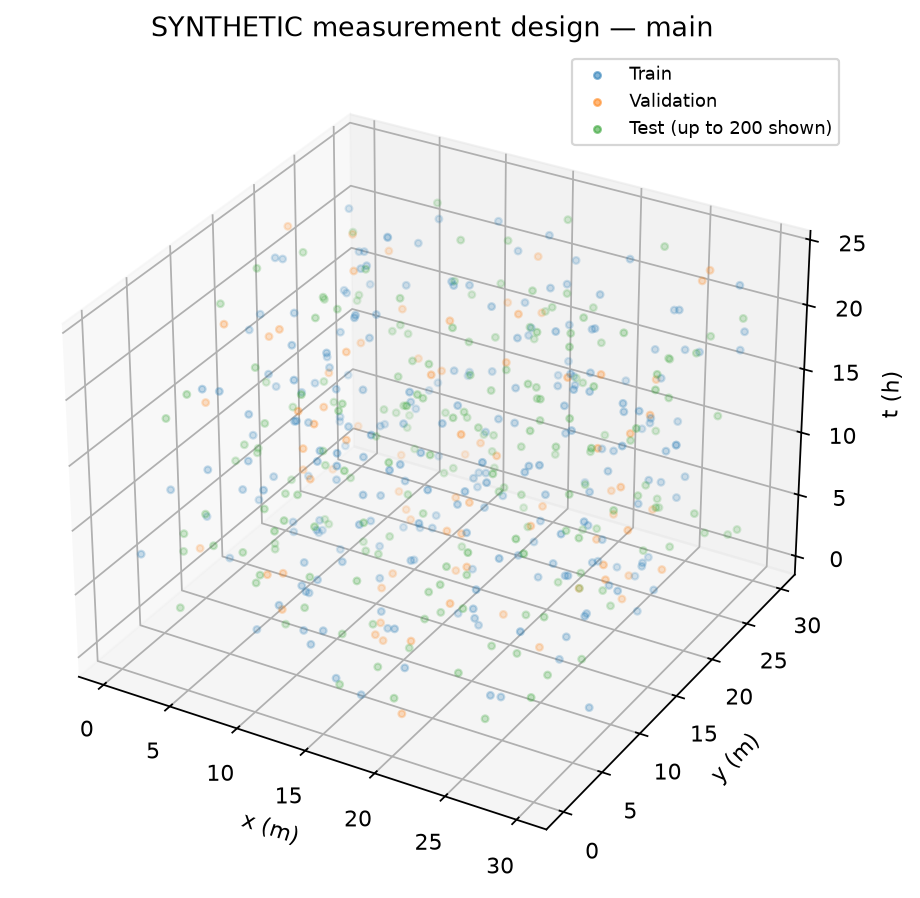

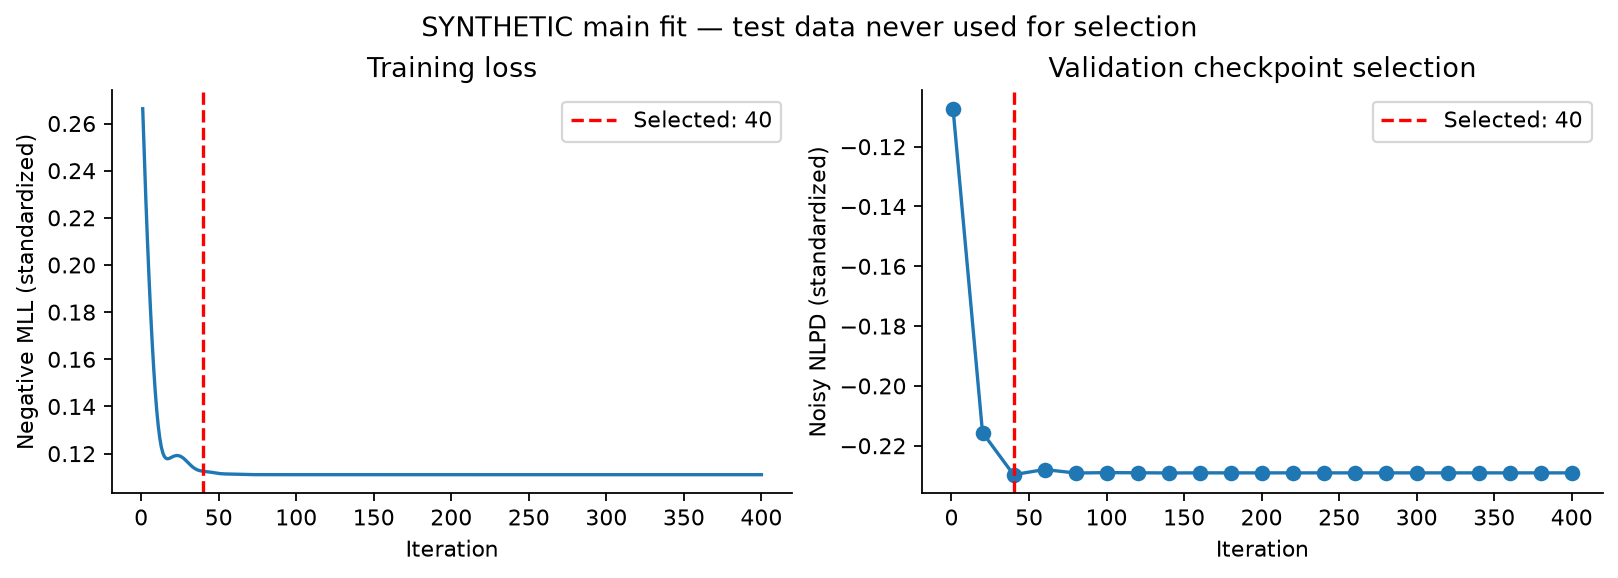

In [4]:
show_test_result("main")
figure(SYN, "samples_main.png")
figure(SYN, "training.png")

At 6, 12 and 18 h, the same `main` model predicts a 51 × 51 spatial grid. Columns show ground truth, posterior mean, latent posterior standard deviation and absolute error. The timestamps are field snapshots, not separate training stages. White dots show training measurements within ±1 h; all training measurements condition the model.


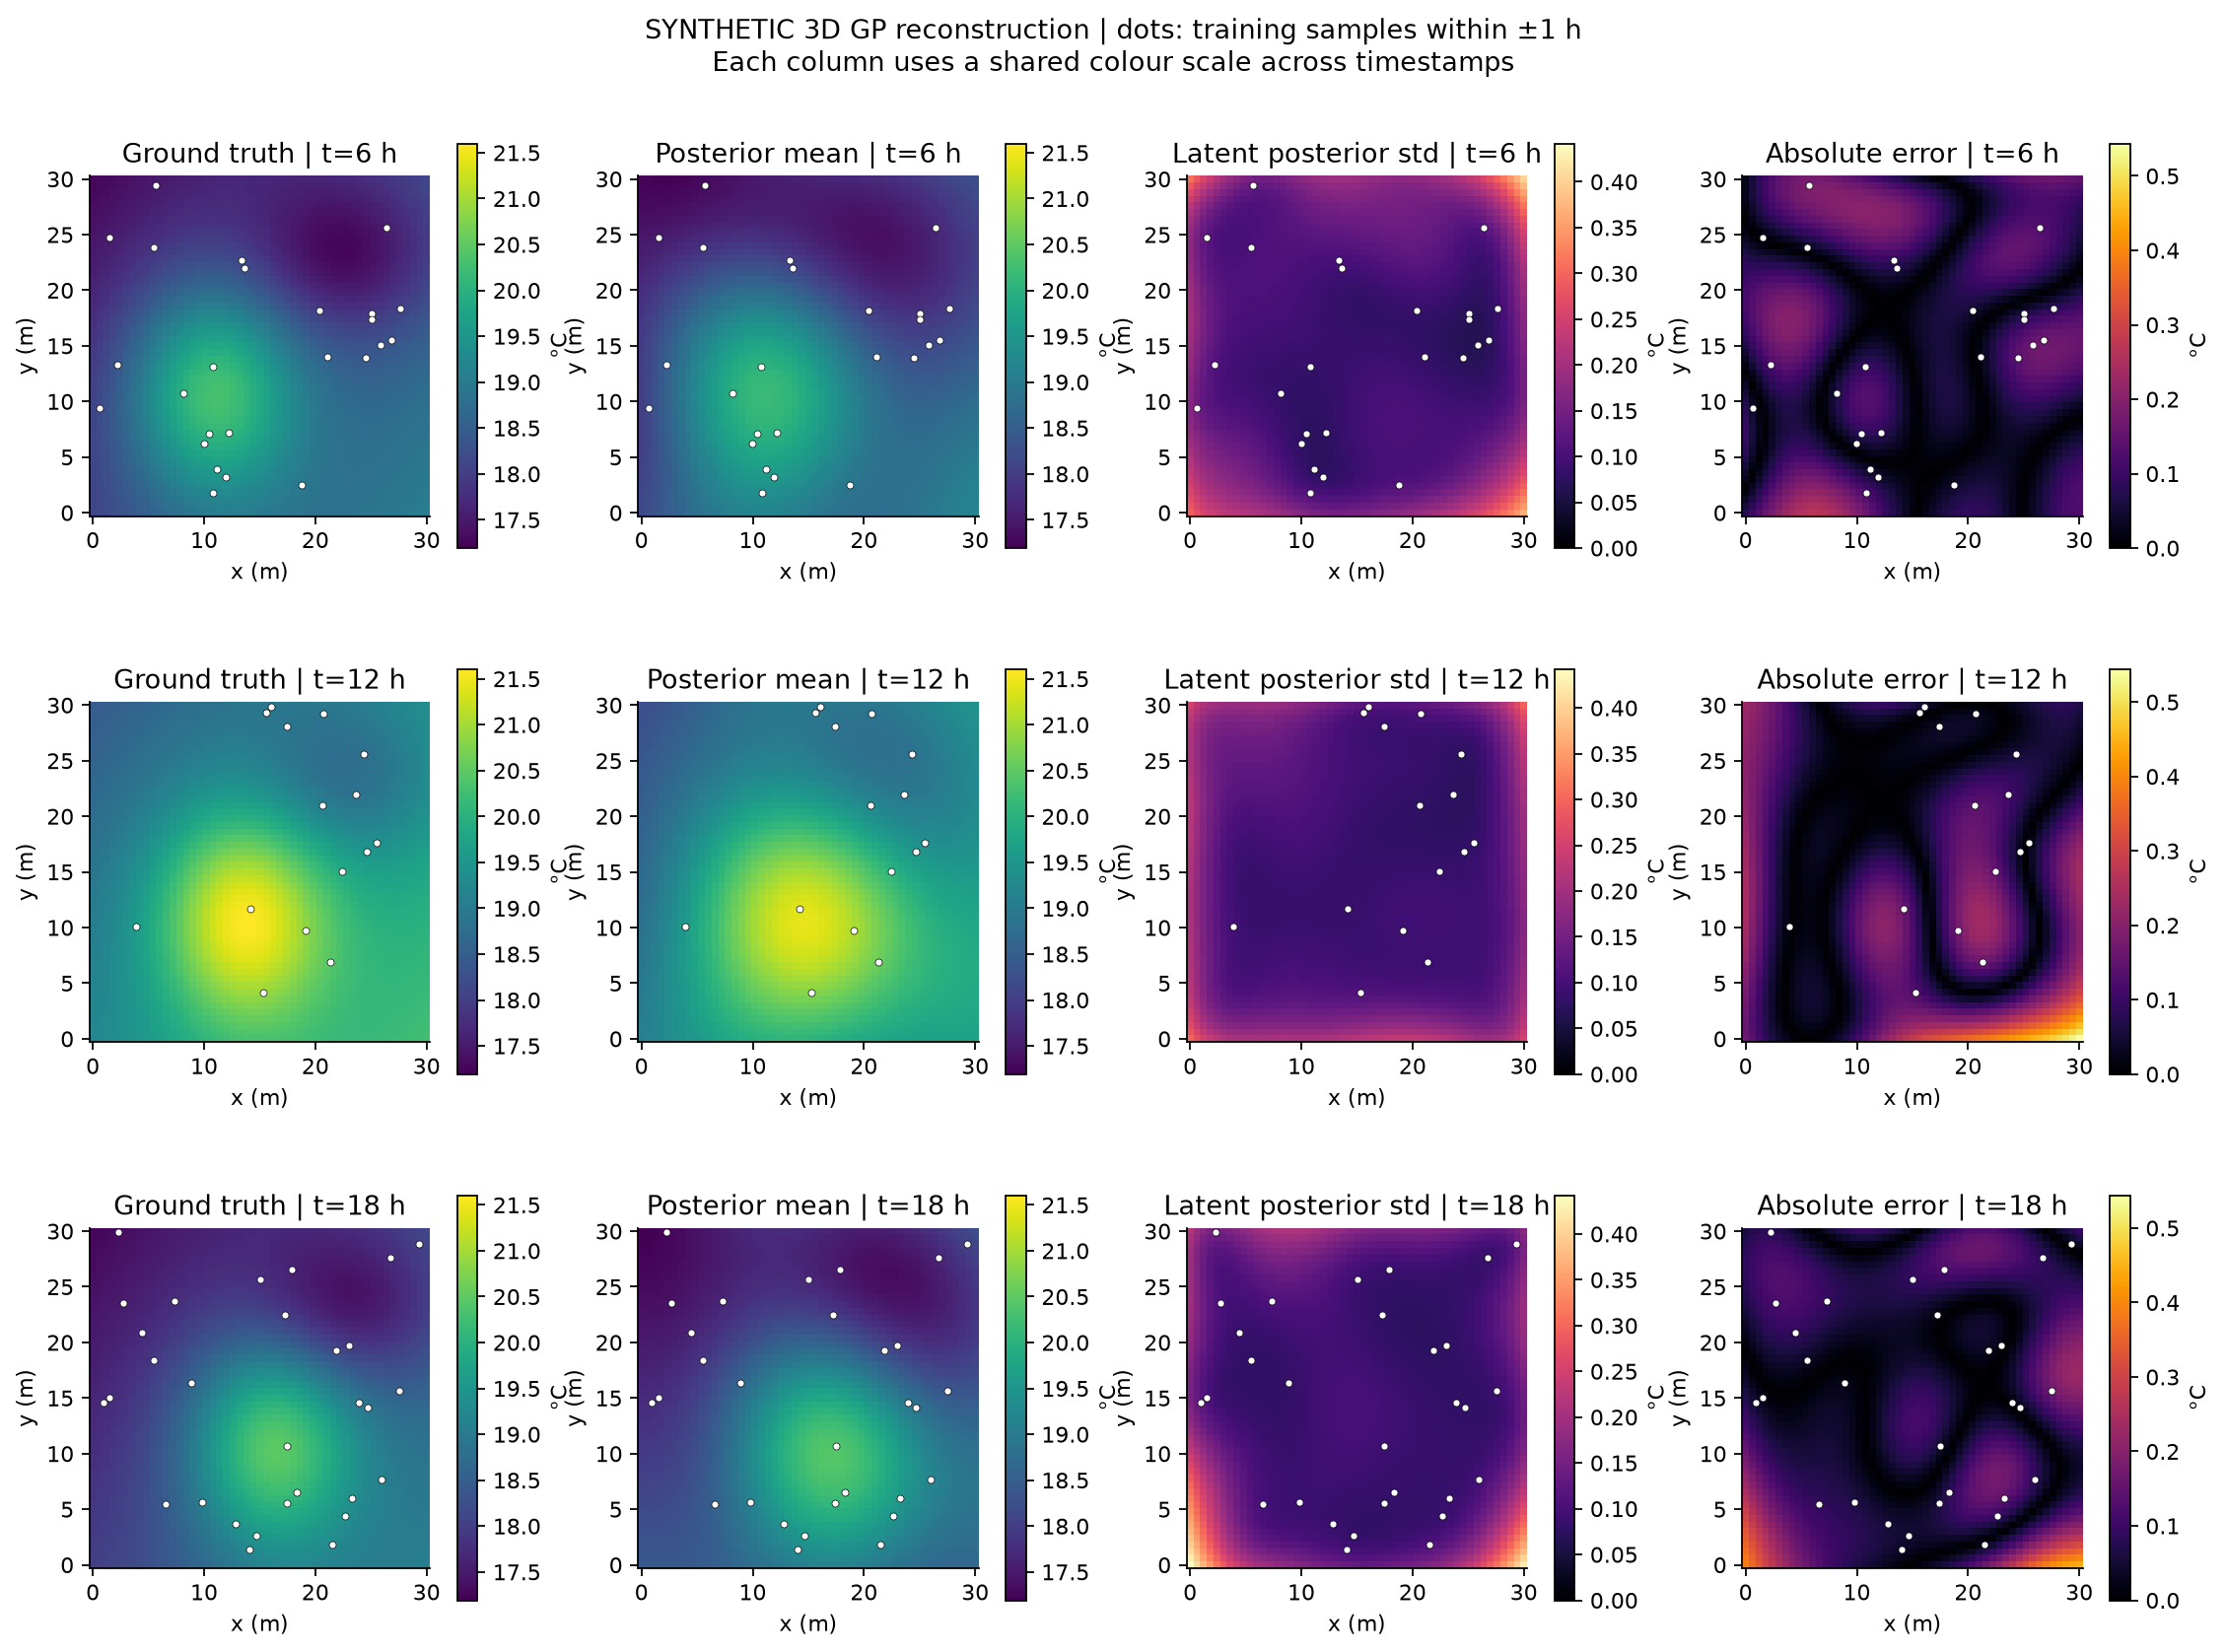

In [5]:
from synthetic_field import snapshot_grid, temperature_true

with np.load(SYN / "snapshot_predictions.npz") as saved:
    for hour in syn_config["snapshot_hours"]:
        _, _, query = snapshot_grid(syn_config["grid_size"], hour, syn_config["domain"])
        posterior = models["main"].predict(query)
        np.testing.assert_allclose(posterior["mean"], saved[f"mean_{hour:g}h"], rtol=1e-9, atol=1e-10)
        np.testing.assert_allclose(posterior["latent_var"], saved[f"latent_var_{hour:g}h"], rtol=1e-9, atol=1e-10)
        np.testing.assert_allclose(temperature_true(query), saved[f"truth_{hour:g}h"])
figure(SYN, "reconstruction_maps.png")

Result: noise-free held-out RMSE 0.110 °C and latent 95% coverage 97.8%. The calibration figure shows nominal versus empirical coverage, standardized observation residuals and posterior mean versus truth. Observation intervals additionally include learned measurement noise.


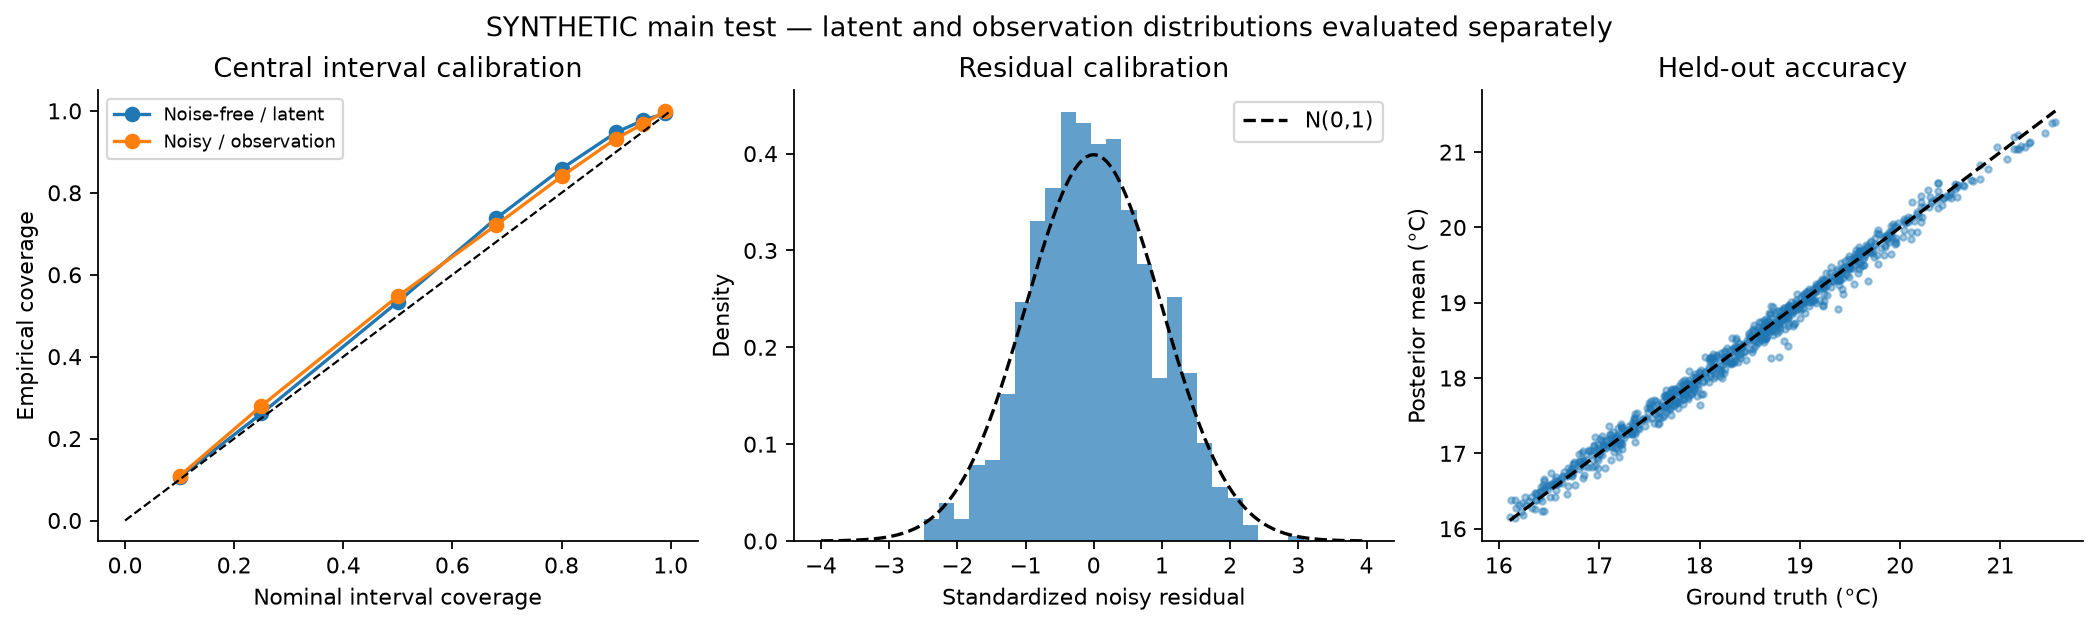

In [6]:
figure(SYN, "calibration.png")

#### Test 2 — Spatial extrapolation

Purpose: predict outside the x-region containing training measurements. Training and validation use x ∈ [0, 18] m; testing uses x ∈ [22, 30] m, with y and time spanning their full ranges. This is spatial extrapolation, not an additional test of the main reconstruction model.

Result: noise-free RMSE 0.663 °C and latent 95% coverage 97.6%; the mean latent 95% interval width is 2.444 °C. Coverage must be interpreted together with interval width. The sampling figure makes the unmeasured x-region explicit; the spatial error panel is shown after Test 3.


protocol,selected_iteration,lengthscales_m_m_h,noise_variance_c2
spatial,180,"[9.813277460617474, 10.862265157166496, 7.203485469227745]",0.0348255


scenario,target,rmse_c,mae_c,coverage_95,nlpd,interval_width_95_c,z_mean,z_std
spatial,latent_truth,0.663181,0.522872,0.97625,0.939003,2.44423,0.690634,0.765918
spatial,noisy_observation,0.692546,0.545663,0.9625,0.992409,2.55936,0.644468,0.804747


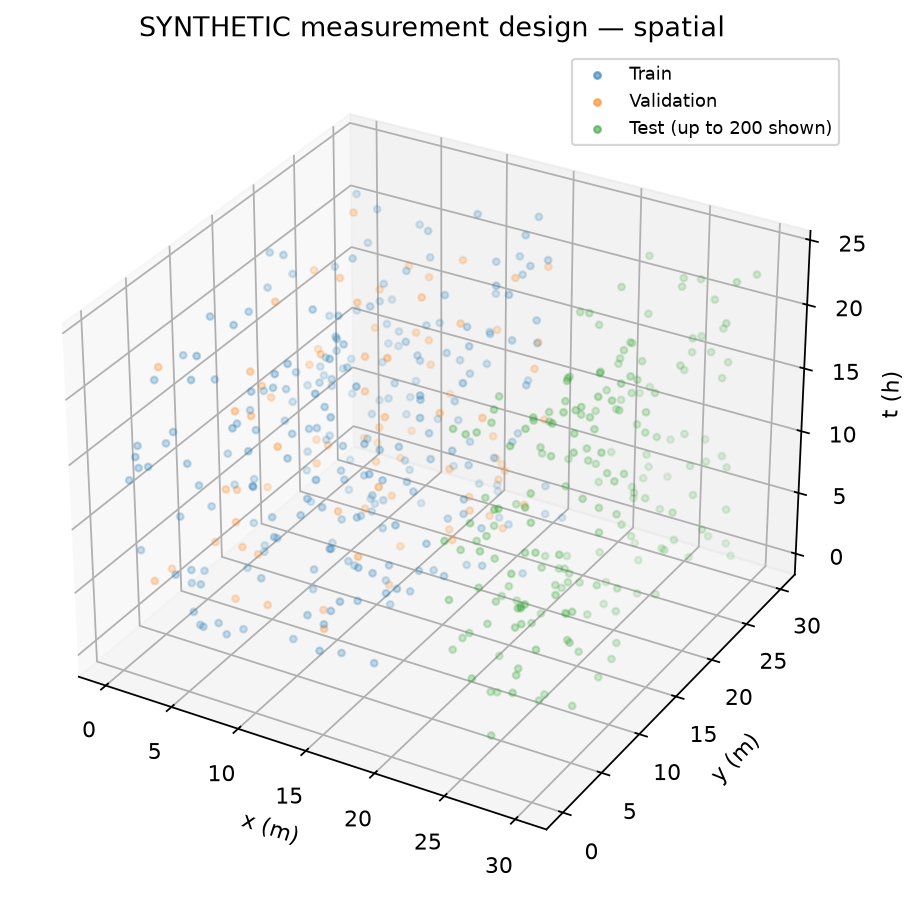

In [7]:
show_test_result("spatial")
figure(SYN, "samples_spatial.png")

#### Test 3 — Future-time temperature prediction

Purpose: predict the field after the training interval. Training uses t ∈ [0, 16] h, validation uses t ∈ [16, 18] h for checkpoint selection, and testing uses t ∈ [18, 24] h. Test observations never condition the model or select its checkpoint. This is a separate fit from the full-domain reconstruction.

Result: noise-free RMSE 0.907 °C and latent 95% coverage 77.1%, indicating undercoverage on this holdout. The horizon table reports errors over 18–20, 20–22 and 22–24 h; RMSE increases from 0.684 to 0.912 to 1.082 °C. `horizon_from_training_end_h` is each bin's upper bound minus 16 h, not its duration.


protocol,selected_iteration,lengthscales_m_m_h,noise_variance_c2
temporal,160,"[8.557239087096294, 11.893288591811908, 7.154891423036316]",0.0479128


scenario,target,rmse_c,mae_c,coverage_95,nlpd,interval_width_95_c,z_mean,z_std
temporal,latent_truth,0.906658,0.818647,0.77125,1.58269,2.27149,-1.4476,0.648449
temporal,noisy_observation,0.918094,0.818757,0.8325,1.49034,2.44159,-1.30503,0.67497


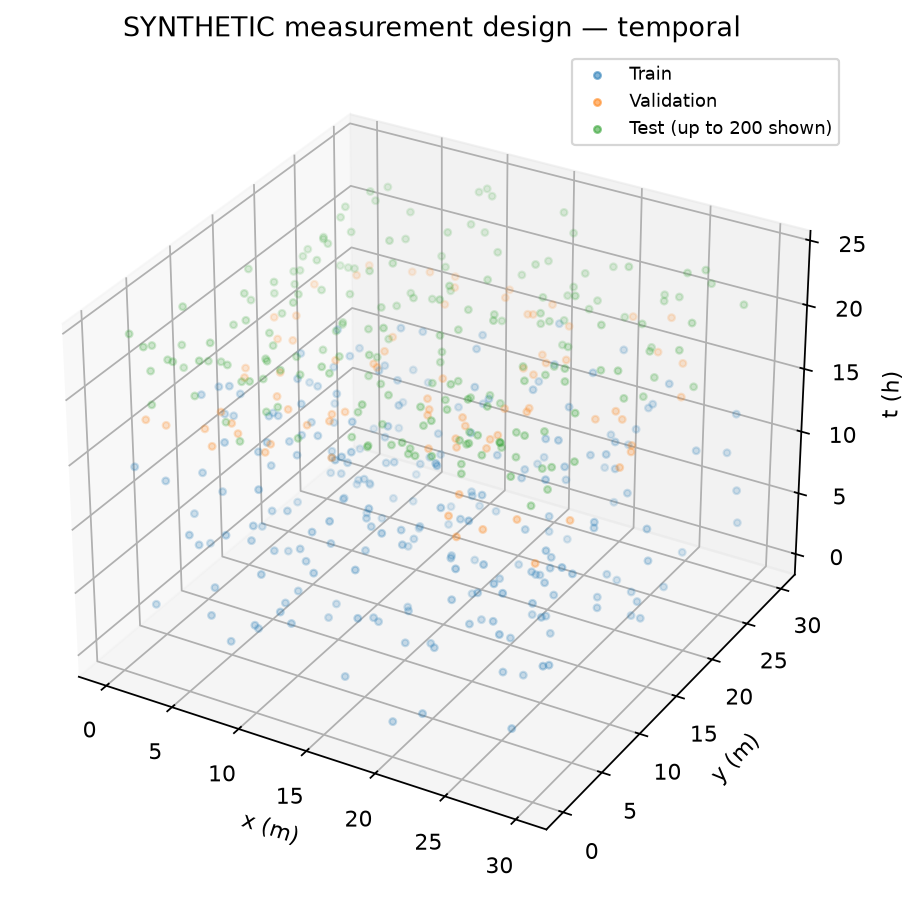

test_start_h,test_end_h,horizon_from_training_end_h,n,rmse_c,mae_c,coverage_95,nlpd,interval_width_95_c,z_mean,z_std
18,20,4,264,0.6844767921348981,0.6299523166078567,0.678030303030303,1.4592329224735328,1.5562891725178731,-1.5908736675836315,0.6695595183657739
20,22,6,276,0.9119837623931776,0.8419054590565485,0.7318840579710145,1.6435960122143847,2.251121378275712,-1.4747718748307832,0.634938299905527
22,24,8,260,1.081992284757603,0.9855548940601588,0.9076923076923077,1.643403936212519,3.0193141291876775,-1.2732664767800281,0.5988514472875305


In [8]:
show_test_result("temporal")
figure(SYN, "samples_temporal.png")
table(rows(SYN / "temporal" / "forecast_horizons.csv"))

Shared error diagnostic for Tests 2 and 3: the left panel shows spatial-extrapolation errors against held-out x; the right panel shows future-prediction errors against time. Blue points are posterior-mean errors relative to noise-free truth; orange points show the corresponding ±1.96 latent posterior standard deviations around zero. These are error/uncertainty plots, not temperature maps.


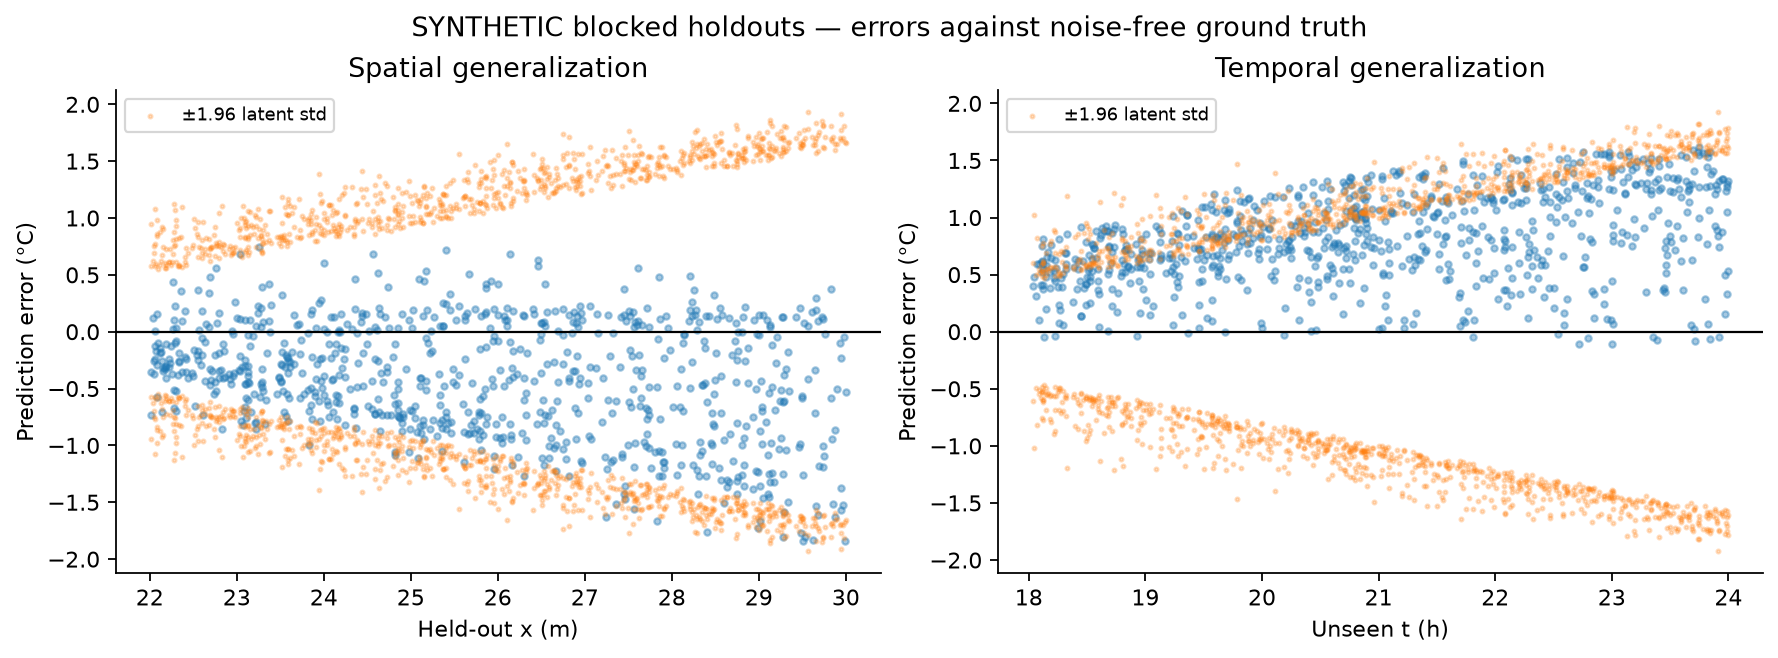

In [9]:
figure(SYN, "generalization.png")

### 1.3 Additional GP sensitivity checks

The same RBF GP was evaluated at three training counts (60, 120, 240), three measurement-noise SDs (0.05, 0.2, 0.5 °C) and three seeds: 27 fits. These are sample/noise sensitivity checks, not alternative prediction methods or additional holdout protocols. The figure reports latent RMSE, coverage and NLPD; error bars are sample standard deviations across three seeds, not confidence intervals. Tables retain both latent and observation metrics.


train_count,noise_std_c,target,runs,rmse_c_mean,rmse_c_std,mae_c_mean,mae_c_std,coverage_95_mean,coverage_95_std,nlpd_mean,nlpd_std,interval_width_95_c_mean,interval_width_95_c_std
60,0.05,latent_truth,3,0.178335412573877,0.021771560258479435,0.12742515935232343,0.01788922221416036,0.9466666666666667,0.041876554697507444,-0.4750094881178207,0.13791899137465177,0.7294775020991136,0.0774434612710658
60,0.05,noisy_observation,3,0.18229894012504566,0.021921896606034854,0.13276282052971702,0.017932515362459482,0.9579166666666666,0.03953505828164839,-0.41354101264061294,0.12917200477784374,0.7739234195582204,0.05762537202953078
120,0.05,latent_truth,3,0.11380517894629244,0.007480693682432165,0.0755887193872143,0.0034227575888003347,0.9541666666666666,0.03262795325075313,-1.1215126965224667,0.08376087734702899,0.37816013813479127,0.03615094138188372
120,0.05,noisy_observation,3,0.12258025523033066,0.005186452850262022,0.08659881323900753,0.0014088020832761926,0.9579166666666666,0.025010414497431552,-0.9071893222243865,0.030137351932775492,0.44225777740322153,0.030943691593727656
240,0.05,latent_truth,3,0.054376478465837506,0.010915572548651385,0.038588473041537875,0.00462878393693979,0.9541666666666666,0.003145764348029471,-1.692529637596371,0.0891938918340574,0.20368556395148638,0.02237771380342418
240,0.05,noisy_observation,3,0.07394134609435069,0.008465188402257242,0.05619505303668094,0.004332749279283554,0.9608333333333333,0.009042722672587765,-1.2545055958206726,0.05613819247503228,0.2996089354408355,0.029303674457483008
60,0.2,latent_truth,3,0.24305912279282985,0.018625167447389325,0.19017031569537432,0.0071455235736808355,0.9533333333333333,0.00954703269782468,-0.04405531396160214,0.04638886795576218,0.994516577740909,0.059412457078063766
60,0.2,noisy_observation,3,0.3078559100271427,0.024826967829298233,0.24230462705315134,0.018908185503189547,0.9495833333333333,0.018214577495328663,0.22541718218671725,0.06266637602282027,1.233085733445752,0.026299826343848767
120,0.2,latent_truth,3,0.1903047089824407,0.013903796023086333,0.14206523000570073,0.008228896367671185,0.9520833333333334,0.051483209236928236,-0.3684550483312737,0.12841723375864542,0.7134917171554692,0.07543228680492446
120,0.2,noisy_observation,3,0.2707974022182253,0.0047408210374421805,0.2121990546192333,0.003167040062598056,0.9508333333333333,0.016266017746619267,0.08263429624615452,0.011850919352452029,1.0645862969979707,0.07521362072835587


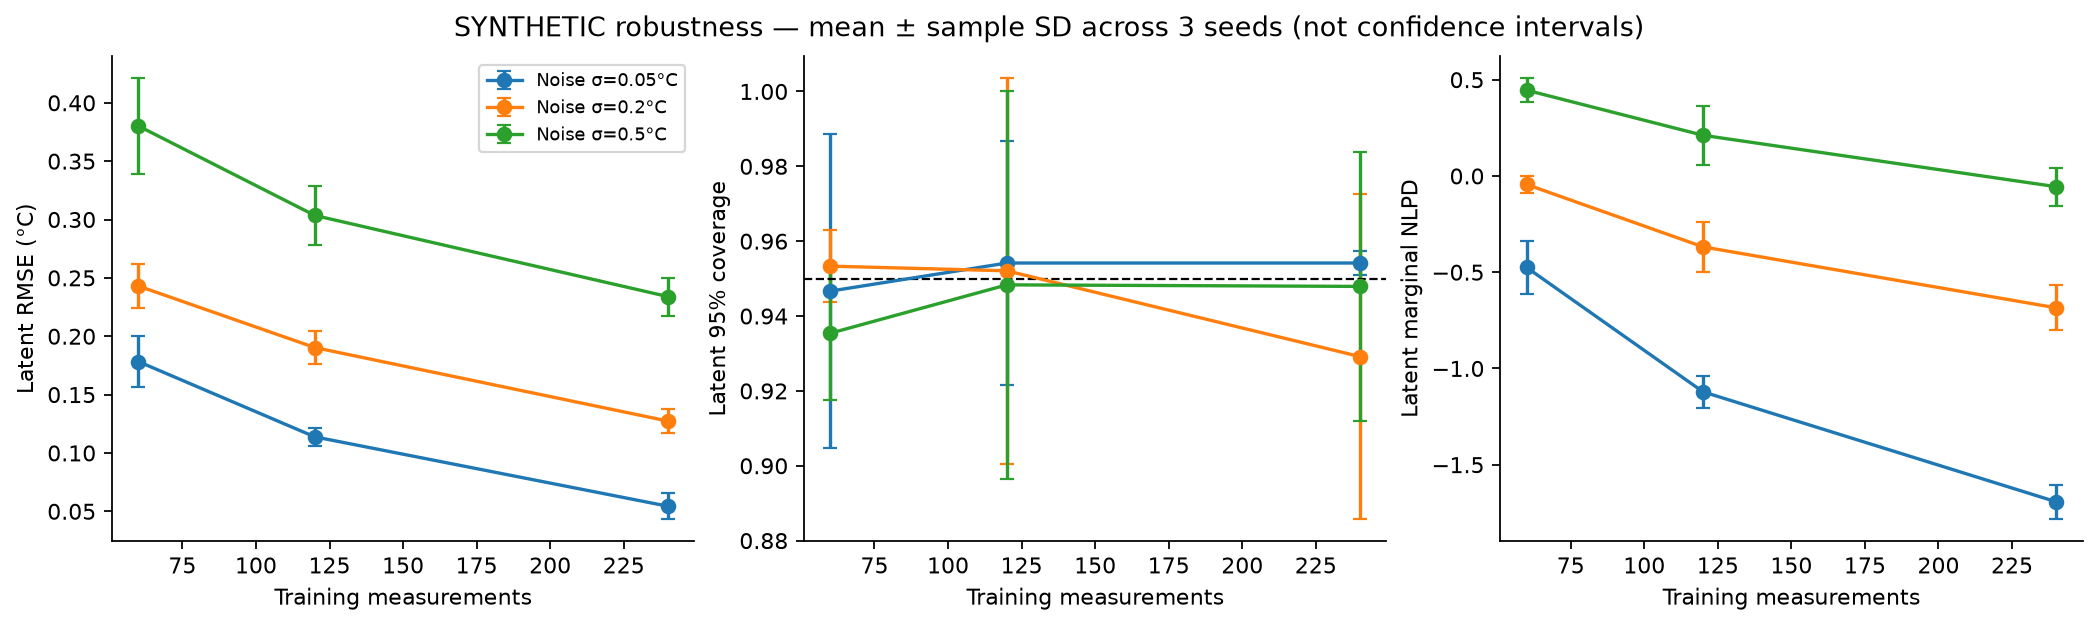

In [10]:
table(rows(SYN / "robustness_summary.csv"))
figure(SYN, "robustness.png")

### 1.4 Conclusion

The following results are evaluated against noise-free synthetic ground truth.

- **In-domain reconstruction:** RMSE 0.110 °C and 95% coverage 97.8%. The RBF GP reconstructs this field with low error from sparse noisy measurements within the sampled space-time domain.
- **Spatial extrapolation:** RMSE 0.663 °C and 95% coverage 97.6%, with a mean 95% interval width of 2.444 °C. Predictions outside the measured x-region have greater error and broad uncertainty intervals; high coverage alone does not establish precise extrapolation.
- **Future-time prediction:** RMSE 0.907 °C and 95% coverage 77.1%. Error increases over the tested forecast horizons, and the intervals under-cover the truth, indicating overconfidence on this holdout.

These tests establish a synthetic RBF GP baseline, not evidence of real spatial reconstruction or robot sampling performance.


## 2. Dashboard temporal reconstruction and prediction

The supplied weather-station export is treated as one temperature series. No spatial coordinates or explicit station identifier are available in this file. Physical sensor count, timezone, sensor accuracy and raw-versus-processed status remain unverified.

The shared Exact GP uses only elapsed time and an RBF kernel. Spatial lengthscales are not inferred.


observations,first_timestamp,last_timestamp,span_h,sampling_interval_min,unique_temperature_values,adjacent_equal_temperature_fraction,temperature_variable,timezone
352,2026-10-14T00:00:00,2026-10-16T10:30:00,58.5,[10.0],77,0.683761,Air Temperature: °C,unspecified in export


{
  "experiment": "real_dashboard_single_station_temporal_rbf",
  "input_csv": "../../../../Data/Dashboard_data/WELLWestCampus_WeatherStation_20261014_20261017.csv",
  "temperature_column": "Air Temperature: \u00b0C",
  "seed": 0,
  "gap_reconstruction": {
    "validation_gap_h": [
      12.0,
      14.0
    ],
    "test_gap_h": [
      36.0,
      40.0
    ]
  },
  "forecast": {
    "development_train_end_h": 36.0,
    "validation_end_h": 48.0,
    "test_start_h": 48.0,
    "refit_on_development_and_validation": true,
    "horizon_bin_h": 2.0
  },
  "training": {
    "iterations": 400,
    "learning_rate": 0.04,
    "validation_every": 20,
    "initial_lengthscale_scaled": 0.8,
    "initial_noise_variance_scaled": 0.02,
    "dtype": "float64",
    "device": "cpu",
    "threads": 1
  }
}

experiment,role,count,first_timestamp,last_timestamp
gap,train,316,2026-10-14T00:00:00,2026-10-16T10:30:00
gap,validation,12,2026-10-14T12:00:00,2026-10-14T13:50:00
gap,test,24,2026-10-15T12:00:00,2026-10-15T15:50:00
forecast,development_train,216,2026-10-14T00:00:00,2026-10-15T11:50:00
forecast,validation,72,2026-10-15T12:00:00,2026-10-15T23:50:00
forecast,refit_train,288,2026-10-14T00:00:00,2026-10-15T23:50:00
forecast,test,64,2026-10-16T00:00:00,2026-10-16T10:30:00


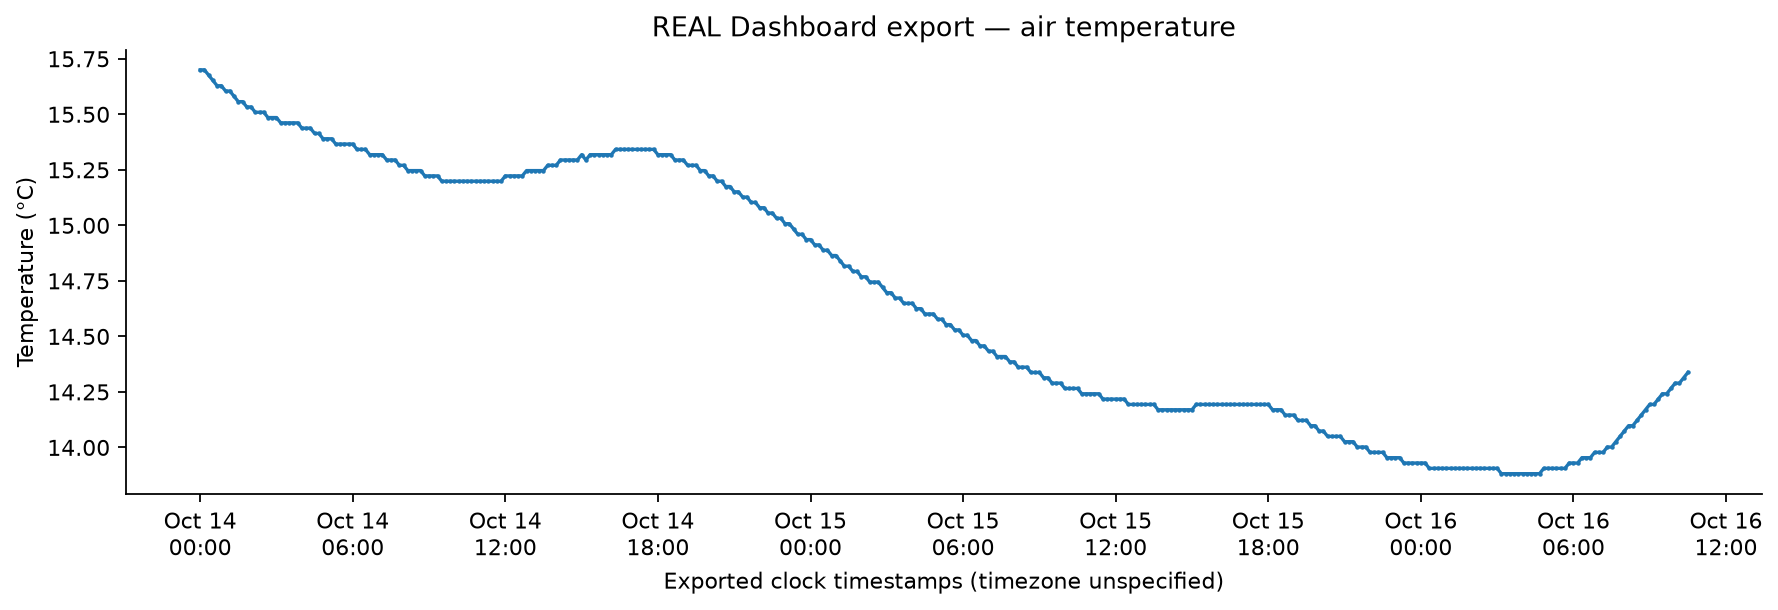

In [11]:
real_config = json.loads((REAL / "config.json").read_text())
audit = json.loads((REAL / "data_audit.json").read_text())
table([{k: audit[k] for k in [
    "observations", "first_timestamp", "last_timestamp", "span_h",
    "sampling_interval_min", "unique_temperature_values",
    "adjacent_equal_temperature_fraction", "temperature_variable", "timezone"]}])
display(Code(json.dumps(real_config, indent=2), language="json"))
table(rows(REAL / "split_manifest.csv"))
figure(REAL, "raw_temperature.png")

### Missing-interval reconstruction

Test: [36, 40) h, 24 observations. Validation: [12, 14) h, 12 observations. Training: the remaining 316 observations. Data on both sides of the test gap are available: this is offline interpolation, not future forecasting.


case,test_count,rmse_c,mae_c,coverage_95,nlpd,interval_width_95_c,z_mean,z_std
gap,24,0.0170691,0.0137788,0.625,-2.31084,0.0402768,-1.08408,1.23357


{
  "kernel": "ScaleKernel(RBF_t), single-location temporal GP",
  "lengthscales_scaled": [
    0.3180865419479229
  ],
  "output_variance_c2": 0.33080540784332435,
  "noise_variance_c2": 8.505562453014516e-05,
  "mean_c": 14.803972182137164,
  "selected_iteration": 160,
  "selection": "minimum validation noisy marginal NLPD; no test selection",
  "fit_seconds": 1.1868408750015078,
  "scaler": {
    "x_mean": [
      29.212025316455698
    ],
    "x_std": [
      17.42230743386289
    ],
    "y_mean": 14.67645027909421,
    "y_std": 0.5871529259377097,
    "fit_source": "training measurements only"
  },
  "lengthscale_h": 5.541801524391038
}

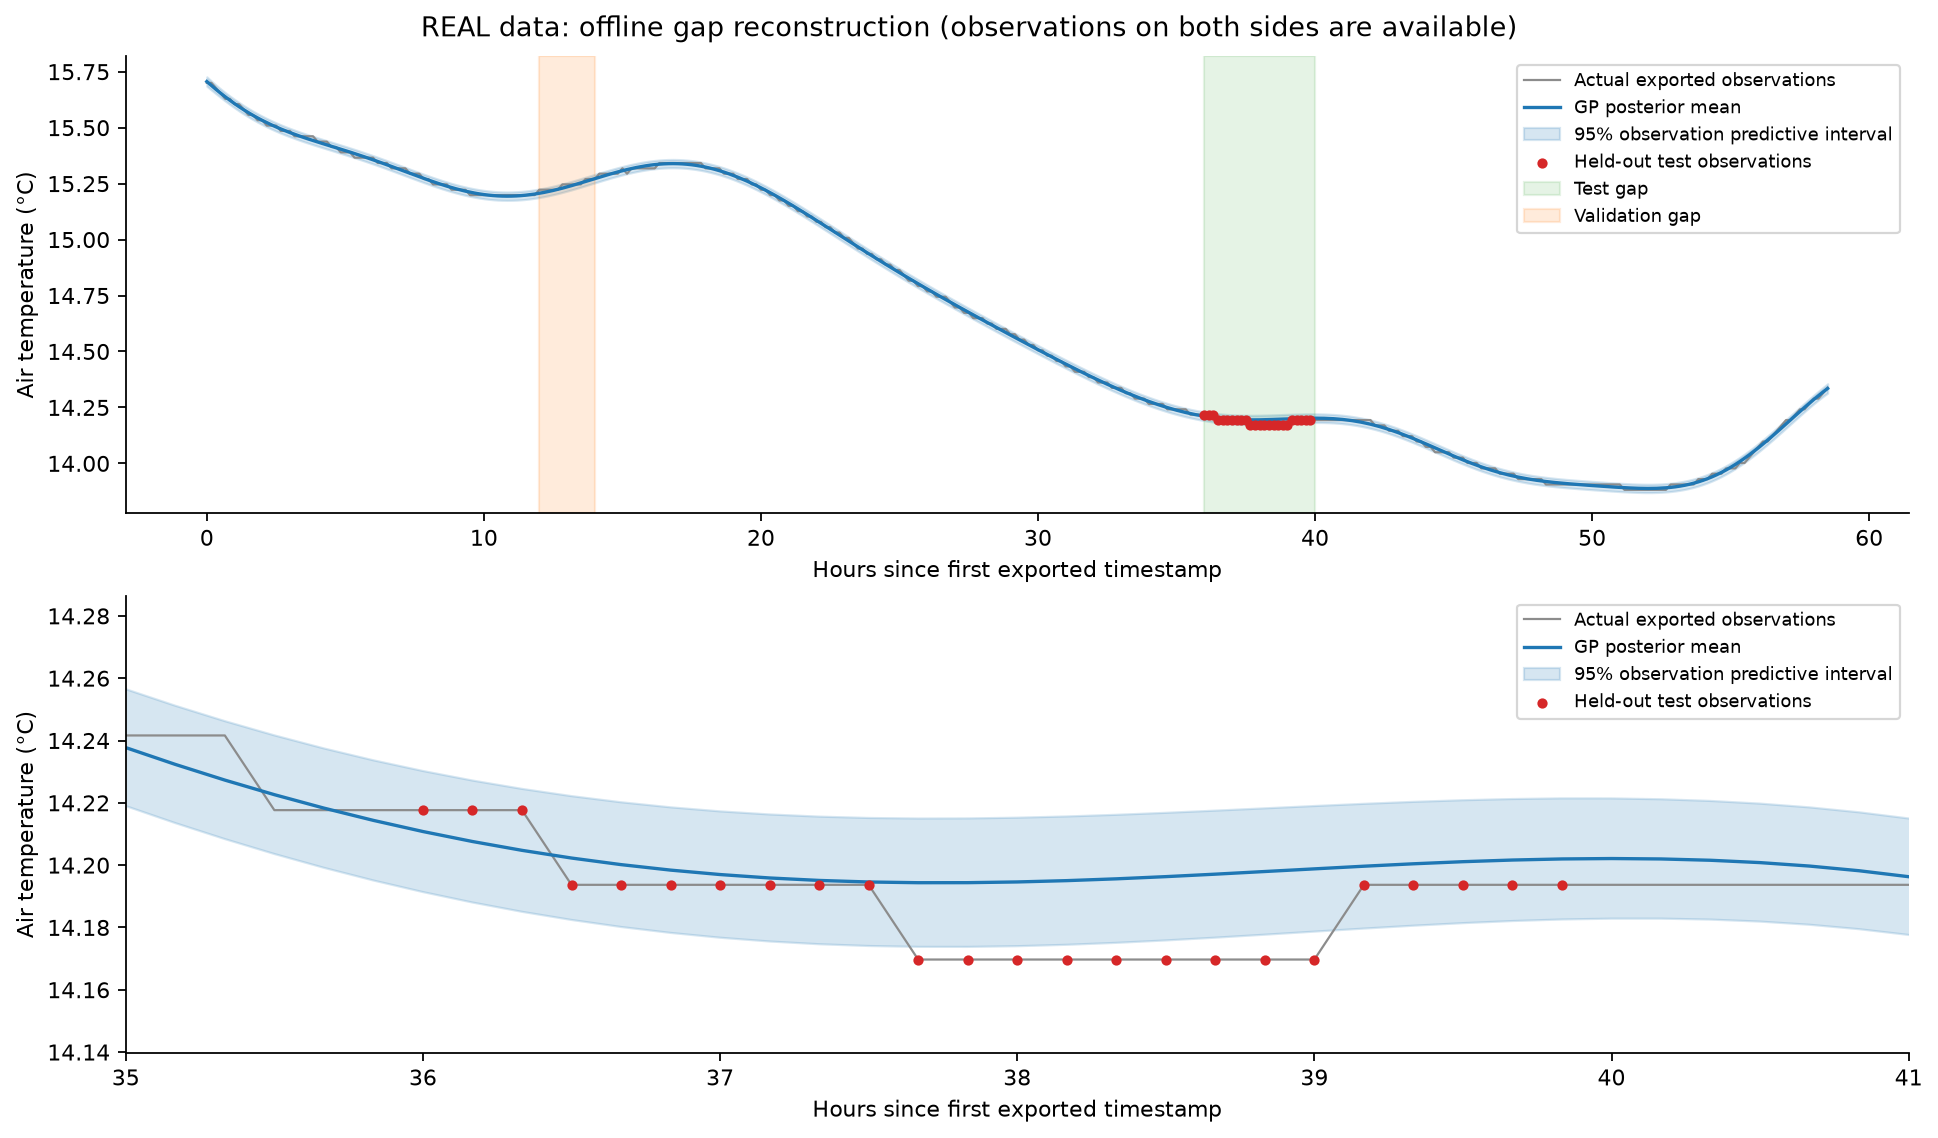

In [12]:
source_csv = REAL / audit["source_name"]
_, dates, time_x, temperature, live_audit = load_data(source_csv, real_config["temperature_column"])
assert live_audit["source_sha256"] == audit["source_sha256"]
parts = split_indices(time_x, real_config)
real_models, real_evaluated = {}, []
for case in ["gap", "forecast"]:
    model = real_models[case] = load_gp(REAL / case / "model.pt")
    ids = parts[case]["test"]
    posterior = model.predict(time_x[ids])
    with np.load(REAL / case / "test_predictions.npz") as saved:
        for key in ["mean", "latent_var", "observed_var"]:
            np.testing.assert_allclose(posterior[key], saved[key], rtol=1e-9, atol=1e-10)
    real_evaluated.append({"case": case, "test_count": len(ids),
                          **distribution_metrics(temperature[ids], posterior["mean"],
                                                 posterior["observed_var"])})
table([real_evaluated[0]])
display(Code(json.dumps(real_models["gap"].hyperparameters(), indent=2), language="json"))
figure(REAL, "gap_reconstruction.png")

### Fixed-origin future prediction

Development training: first 36 h (216 observations). Validation: [36, 48) h (72 observations). Validation selects the training-iteration budget; the final GP is refitted on the first 48 h (288 observations) for that fixed budget. The following 64 observations are tested without updates.

One fixed-origin forecast is evaluated at 64 timestamps spaced 10 minutes apart, from Oct 16, 2026 at 00:00 to 10:30. The last training observation is Oct 15 at 23:50, so forecast horizons range from 10 minutes to 10 h 40 min. No new observations are incorporated during this forecast; this is not rolling prediction.

Validation selected iteration 1. The recorded forecast is therefore a preliminary, early-checkpoint result, not evidence of converged hyperparameter estimation. Test results were not used to revise this choice.


case,test_count,rmse_c,mae_c,coverage_95,nlpd,interval_width_95_c,z_mean,z_std
forecast,64,0.306566,0.250784,0.953125,0.0182718,0.65306,1.31339,0.494843


{
  "kernel": "ScaleKernel(RBF_t), single-location temporal GP",
  "lengthscales_scaled": [
    0.7781713751197226
  ],
  "output_variance_c2": 0.29230115985294336,
  "noise_variance_c2": 0.005480520738008471,
  "mean_c": 14.790044614480921,
  "selected_iteration": 1,
  "selection": "fixed iteration count selected before refit; no test selection",
  "fit_seconds": 0.0031759170014993288,
  "scaler": {
    "x_mean": [
      23.916666666666668
    ],
    "x_std": [
      13.856322931614477
    ],
    "y_mean": 14.81140016146546,
    "y_std": 0.5338924200990096,
    "fit_source": "training measurements only"
  },
  "lengthscale_h": 10.782593869797383
}

horizon_start_h,horizon_end_h,n,rmse_c,mae_c,coverage_95,nlpd,interval_width_95_c,z_mean,z_std
0.0,2.0,12,0.04817892571459245,0.042308335858328494,1.0,-1.4054991568245285,0.32987130956272703,0.4917362986478134,0.24829562279414621
2.0,4.0,12,0.1204646580424621,0.1194978153840552,1.0,-0.6926897246824959,0.414002140834359,1.1283610312173438,0.07876742853059288
4.0,6.0,12,0.19304405387773305,0.19078688274450428,1.0,-0.1524266558063186,0.565545440367121,1.3152670396101145,0.09002630419201975
6.0,8.0,12,0.30602114064528235,0.30362228906125194,1.0,0.4733271090210726,0.772173757127221,1.5363282072938922,0.06992808116301587
8.0,10.0,12,0.48786653269206615,0.48515993192994306,0.9166666666666666,1.3269379012263605,1.010080288103037,1.878155306928866,0.07432452019251817
10.0,12.0,4,0.5885903024382669,0.5884212592822089,0.5,1.6434000139695835,1.1739358268513247,1.9647498038589646,0.021923371690651536


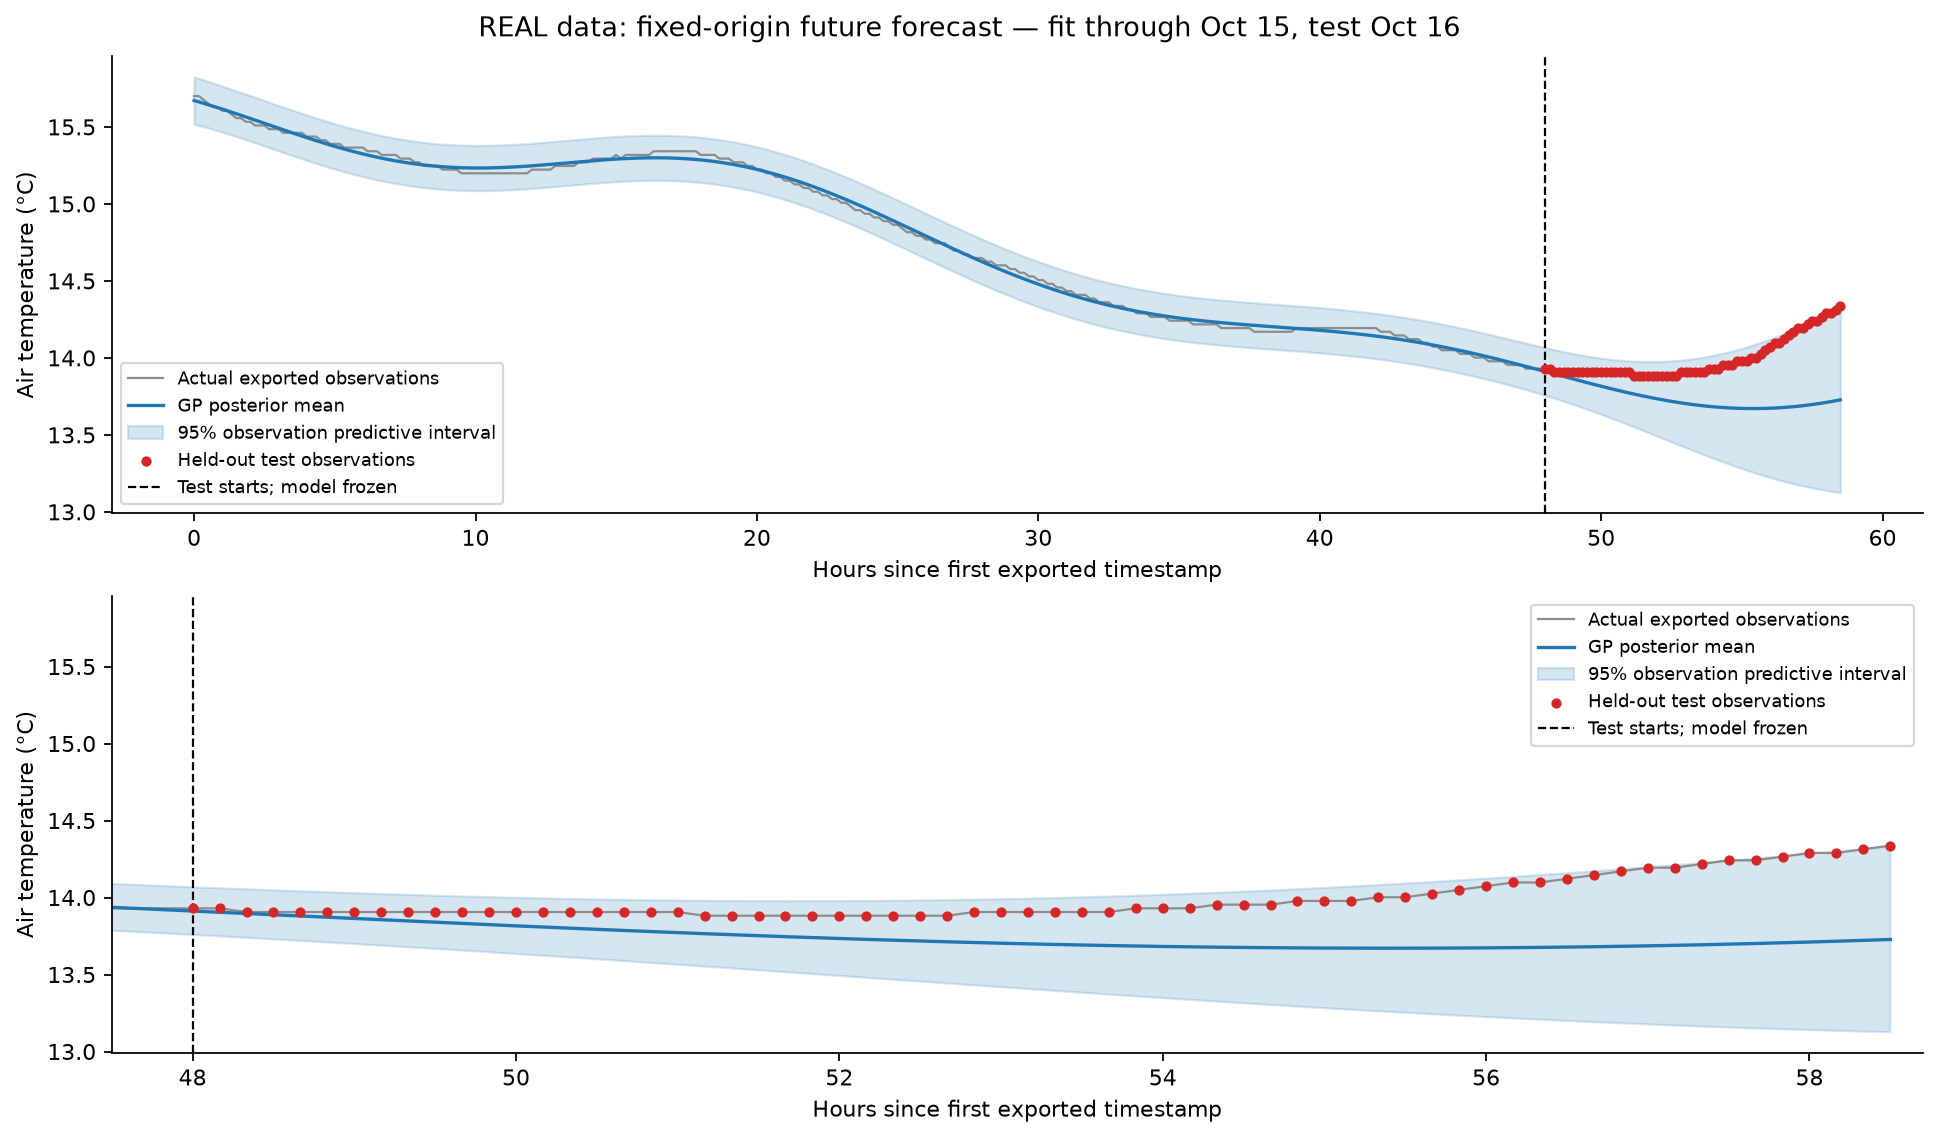

In [13]:
table([real_evaluated[1]])
display(Code(json.dumps(real_models["forecast"].hyperparameters(), indent=2), language="json"))
table(rows(REAL / "forecast" / "forecast_horizons.csv"))
figure(REAL, "future_forecast.png")

### Predictive uncertainty and result notes

The shaded intervals and coverage metrics include learned observation noise. The true latent temperature is unknown. A single short, correlated time series and one forecast origin cannot establish general calibration.


case,test_count,rmse_c,mae_c,coverage_95,nlpd,interval_width_95_c,z_mean,z_std
gap,24,0.0170691,0.0137788,0.625,-2.31084,0.0402768,-1.08408,1.23357
forecast,64,0.306566,0.250784,0.953125,0.0182718,0.65306,1.31339,0.494843


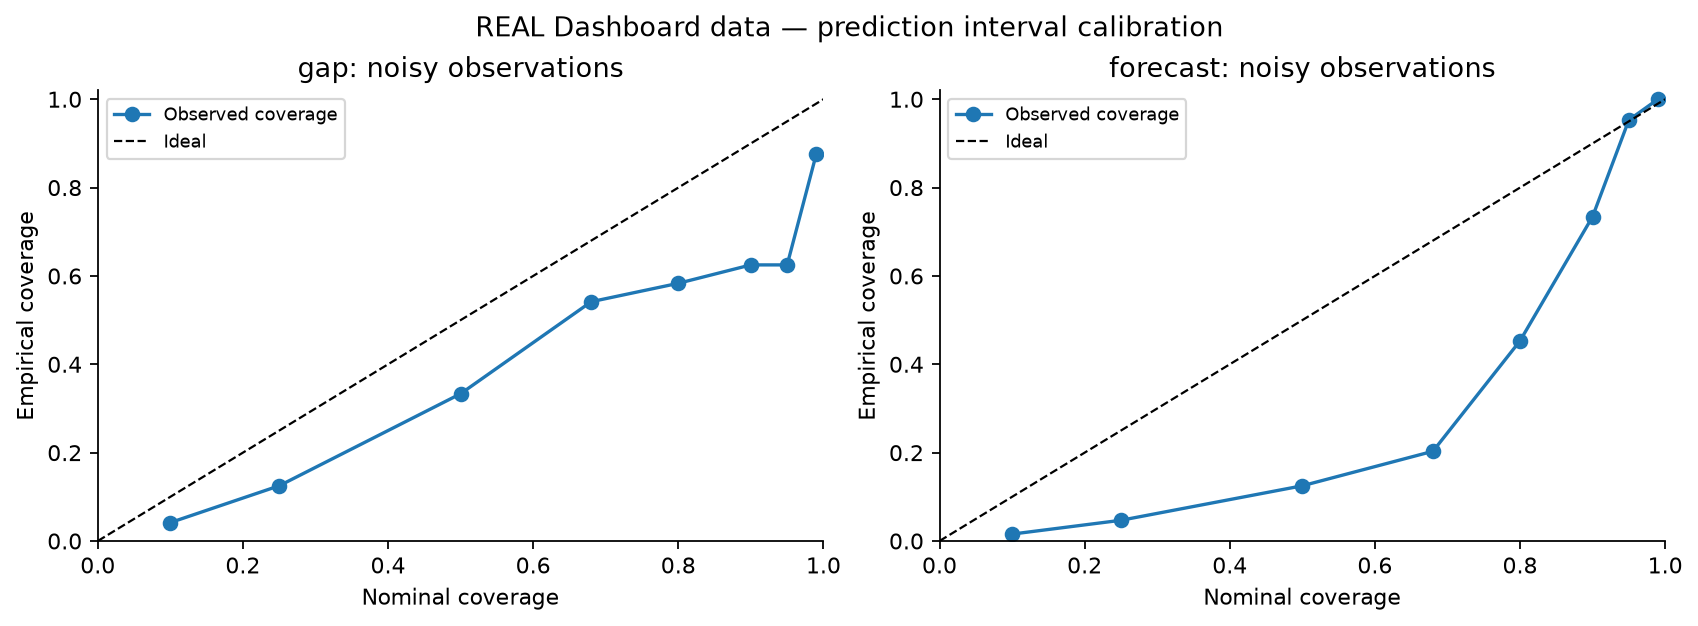

In [14]:
for computed in real_evaluated:
    recorded = next(r for r in rows(REAL / "metrics.csv") if r["case"] == computed["case"])
    for key in ["rmse_c", "mae_c", "coverage_95", "nlpd", "interval_width_95_c", "z_mean", "z_std"]:
        np.testing.assert_allclose(computed[key], float(recorded[key]), rtol=1e-8, atol=1e-9)
table(real_evaluated)
figure(REAL, "calibration.png")

### 2.4 Conclusion

The following results are evaluated against held-out Dashboard observations; the true latent temperature is unknown.

- **Missing-interval reconstruction:** RMSE 0.0171 °C and 95% coverage 62.5%, with a mean 95% interval width of 0.0403 °C. The GP reconstructs the withheld observations with low error, but its intervals are too narrow on this gap. This is offline reconstruction using measurements on both sides, not future forecasting.
- **Future-time prediction:** RMSE 0.3066 °C and 95% coverage 95.3%. Error increases with forecast horizon on this holdout. Overall coverage is close to 95%, but does not establish reliable calibration at every horizon or on other days.

These results establish a preliminary real-data temporal RBF GP baseline. Validation selected iteration 1, so converged hyperparameter estimation has not been demonstrated. One short series and one forecast origin do not validate general forecasting performance or real 3D spatial reconstruction.


## Appendix: implementation references

The source files are linked below rather than reproduced. Both experiments reuse the shared GP implementation. The result cells above replay saved checkpoints without retraining.

### Shared GP and synthetic-field implementation

| Source file                                                                                                                 | Purpose                                                                                             |
| --------------------------------------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------------- |
| [gp_model.py](10.16_testing_code/3D_time%26spatial%20temp%20field%20rebuild%20%26%20prediction/gp_model.py)                 | Exact GP, RBF kernels, training-only scaling, fitting, posterior prediction and checkpoint loading. |
| [synthetic_field.py](10.16_testing_code/3D_time%26spatial%20temp%20field%20rebuild%20%26%20prediction/synthetic_field.py)   | Known synthetic temperature field and reproducible sparse noisy measurements.                       |
| [evaluation.py](10.16_testing_code/3D_time%26spatial%20temp%20field%20rebuild%20%26%20prediction/evaluation.py)             | Temperature-error and predictive-uncertainty metrics.                                               |
| [plots.py](10.16_testing_code/3D_time%26spatial%20temp%20field%20rebuild%20%26%20prediction/plots.py)                       | Synthetic field, reconstruction, calibration and holdout diagnostic figures.                        |
| [experiment_paths.py](10.16_testing_code/3D_time%26spatial%20temp%20field%20rebuild%20%26%20prediction/experiment_paths.py) | Shared source and result-folder locations.                                                          |

### Experiment workflows, configuration and checks

| Source file                                                                                                           | Purpose                                                                                          |
| --------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------ |
| [experiment.py](10.16_testing_code/3D_time%26spatial%20temp%20field%20rebuild%20%26%20prediction/experiment.py)       | Synthetic reconstruction, spatial extrapolation, future prediction and sensitivity-run workflow. |
| [config.json](10.16_testing_code/3D_time%26spatial%20temp%20field%20rebuild%20%26%20prediction/config.json)           | Synthetic field, sampling, splits and training settings.                                         |
| [test_baseline.py](10.16_testing_code/3D_time%26spatial%20temp%20field%20rebuild%20%26%20prediction/test_baseline.py) | Synthetic generation, GP covariance, split and checkpoint checks.                                |
| [dashboard_experiment.py](10.16_testing_code/dashboard%20time%20temp%20prediction/dashboard_experiment.py)            | Real-data audit, missing-interval reconstruction and chronological forecasting workflow.         |
| [dashboard_config.json](10.16_testing_code/dashboard%20time%20temp%20prediction/dashboard_config.json)                | Dashboard input, temporal splits and training settings.                                          |
| [test_dashboard.py](10.16_testing_code/dashboard%20time%20temp%20prediction/test_dashboard.py)                        | Temporal split, kernel, refit and checkpoint checks.                                             |
